# Nexar Collision Prediction — Dataset Exploration

**Computer Vision Project**

## Goal

Understand the Nexar Collision Prediction dataset before implementing
the collision-prediction pipeline.

This notebook investigates:

- Dataset size
- Class balance
- Positive and negative examples
- Event timestamps
- Alert timestamps
- Alert lead time
- Distribution of event times
- Relationship between CSV IDs and video files
- Potential data-quality issues

The original videos will **not** be modified or preprocessed in this notebook.

The purpose of this notebook is to understand the dataset before designing
the training and evaluation pipeline.

## 1. Imports and Setup

We first import the Python libraries needed for basic dataset exploration.

We are using:

- `pandas` for reading and analysing the CSV file
- `numpy` for numerical operations
- `matplotlib` for visualisation
- `pathlib` for working with file paths

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

### Why these libraries?

**Pandas** allows us to treat the CSV file like a spreadsheet and perform
operations such as filtering rows and calculating statistics.

**NumPy** provides numerical functionality that will also be useful later
when working with video frames and machine-learning data.

**Matplotlib** allows us to create plots so that we can visually inspect
the dataset.

**Pathlib** gives us a clean way of constructing file and directory paths
without manually writing long strings.

In [22]:
DATA_DIR = Path("./data/raw")

print("Dataset directory:")
print(DATA_DIR.resolve())

Dataset directory:
/Users/rameez/Documents/Wits Stuff/Honours/Computer Vision/nexar-collision-prediction/data/raw


In [23]:
print("Files/directories:")

for item in DATA_DIR.iterdir():
    print(item.name)

Files/directories:
.DS_Store
test
test.csv
train
train.csv
sample_submission.csv


## 2. Loading the Training Metadata

The training videos are accompanied by `train.csv`.

The CSV contains metadata associated with each training video.

We will first inspect this metadata before opening any videos.

In [24]:
train_csv = DATA_DIR / "train.csv"

df = pd.read_csv(train_csv)

df.head()

,id,time_of_event,time_of_alert,target
0,1924,NaN,NaN,0
1,822,19.5,18.633,1
2,1429,NaN,NaN,0
3,208,19.8,19.233,1
4,1904,NaN,NaN,0


In [25]:
print("Rows:", len(df))
print("Columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

Rows: 1500
Columns: 4

Column names:
['id', 'time_of_event', 'time_of_alert', 'target']


### Initial observation

The training metadata contains 1,500 rows and four columns:

- `id` — identifies the video
- `time_of_event` — timestamp of the collision/near-miss event
- `time_of_alert` — timestamp at which the dangerous situation becomes
  recognizable
- `target` — binary target indicating whether the video is positive or
  negative

The meaning of the timestamps will be investigated further below.

In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             1500 non-null   int64  
 1   time_of_event  750 non-null    float64
 2   time_of_alert  750 non-null    float64
 3   target         1500 non-null   int64  
dtypes: float64(2), int64(2)
memory usage: 47.0 KB


## 3. Missing Values

Missing values are important to investigate because timestamps may only
exist for positive examples.

For example, a normal-driving video does not have a collision event, so
we would expect `time_of_event` and `time_of_alert` to be empty for those
videos.

We therefore need to distinguish between:

- genuinely missing/incorrect data
- missing values that are meaningful because the event does not exist

In [27]:
df.isna().sum()

id                 0
time_of_event    750
time_of_alert    750
target             0
dtype: int64

### Observation

There are 750 missing values in both `time_of_event` and `time_of_alert`.

This corresponds exactly to the 750 negative examples.

Therefore, the missing timestamps appear to be associated with videos that
do not contain a collision/near-miss event.

We should **not automatically remove these rows**. The missing values carry
meaning: they identify videos for which there is no event timestamp.

## 4. Class Distribution

The `target` column identifies the class of each training video.

We now determine how many examples belong to each class.

This is important because a heavily imbalanced dataset can make accuracy
misleading.

In [28]:
print(df["target"].value_counts())

target
0    750
1    750
Name: count, dtype: int64


In [29]:
print(df["target"].value_counts(normalize=True))

target
0    0.5
1    0.5
Name: proportion, dtype: float64


### Observation

The training dataset is perfectly balanced:

- 750 negative videos (`target = 0`)
- 750 positive videos (`target = 1`)

Therefore:

- 50% of the training videos are negative
- 50% are positive

This means that a classifier that always predicts one class would achieve
50% accuracy.

However, accuracy will not be our primary evaluation measure. Collision
prediction is concerned with detecting dangerous events while controlling
false alarms, so precision, recall and a threshold-independent metric such
as average precision/AUPRC will be more informative for the final
experiments.

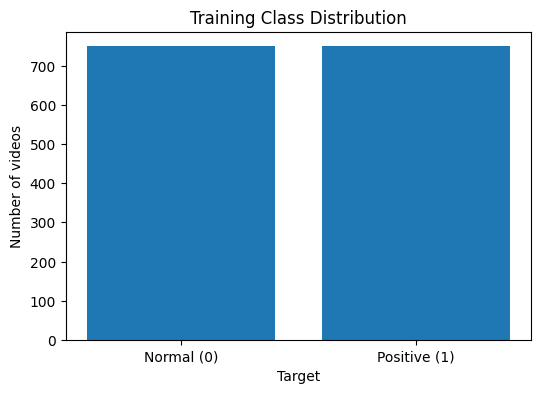

In [30]:
class_counts = df["target"].value_counts().sort_index()

plt.figure(figsize=(6, 4))

plt.bar(
    ["Normal (0)", "Positive (1)"],
    class_counts.values
)

plt.xlabel("Target")
plt.ylabel("Number of videos")
plt.title("Training Class Distribution")

plt.show()

## 5. Positive Videos

We now isolate the positive examples.

A positive video has:

```text
target = 1
```

These videos contain either a collision or near-miss event according to
the dataset's target definition.

The positive videos are particularly important because they contain the
event timestamps that allow us to construct time-to-event experiments.

In [31]:
positive = df[df["target"] == 1].copy()

positive.head(10)

,id,time_of_event,time_of_alert,target
1,822,19.500,18.633,1
3,208,19.800,19.233,1
5,72,20.101,20.068,1
8,128,19.267,18.333,1
10,205,21.146,18.196,1
13,408,19.953,17.551,1
14,948,20.287,19.219,1
15,457,19.600,19.367,1
19,471,19.833,18.267,1
21,900,21.177,17.942,1


In [32]:
print("Positive videos:", len(positive))

print("\nEvent time:")
print(positive["time_of_event"].describe())

print("\nAlert time:")
print(positive["time_of_alert"].describe())

Positive videos: 750

Event time:
count    750.000000
mean      19.101628
std        3.565120
min        3.032000
25%       19.133000
50%       19.802000
75%       20.333000
max       56.800000
Name: time_of_event, dtype: float64

Alert time:
count    750.000000
mean      17.501271
std        3.658975
min        1.966000
25%       17.290000
50%       18.259000
75%       18.977500
max       55.467000
Name: time_of_alert, dtype: float64


### Observation

Most positive events occur around the 20-second region, but event times
vary considerably.

The earliest event occurs at approximately 3 seconds, while the latest
occurs at approximately 56.8 seconds.

Therefore, the experiment must use the **actual `time_of_event` for each
video** rather than assuming that the event occurs at a fixed time.

The same applies to `time_of_alert`.

## 6. Alert Lead Time

The dataset provides both an event time and an alert time.

We define:

    alert lead time = time_of_event - time_of_alert

This represents how far before the event the dangerous situation became
recognizable according to the dataset's alert annotation.

For example:

    event = 19.500 s
    alert = 18.633 s

Therefore:

    lead time = 19.500 - 18.633
              = 0.867 s

In [33]:
positive["alert_lead_time"] = (
    positive["time_of_event"] - positive["time_of_alert"]
)

positive["alert_lead_time"].describe()

count    750.000000
mean       1.600357
std        0.866063
min        0.033000
25%        0.986250
50%        1.433000
75%        2.089500
max        4.466000
Name: alert_lead_time, dtype: float64

### Observation

The alert lead time varies substantially between videos.

Summary:

- Mean: approximately 1.60 seconds
- Median: approximately 1.43 seconds
- Middle 50%: approximately 0.99–2.09 seconds
- Minimum: approximately 0.03 seconds
- Maximum: approximately 4.47 seconds

The median alert lead time of approximately 1.43 seconds makes the
1.5-second prediction horizon particularly interesting for our planned
experiment.

However, the alert time is not identical across videos. Therefore, we
should not treat 1.5 seconds as a universal human-warning threshold.

Instead, it provides useful context for interpreting our
time-to-event experiments.

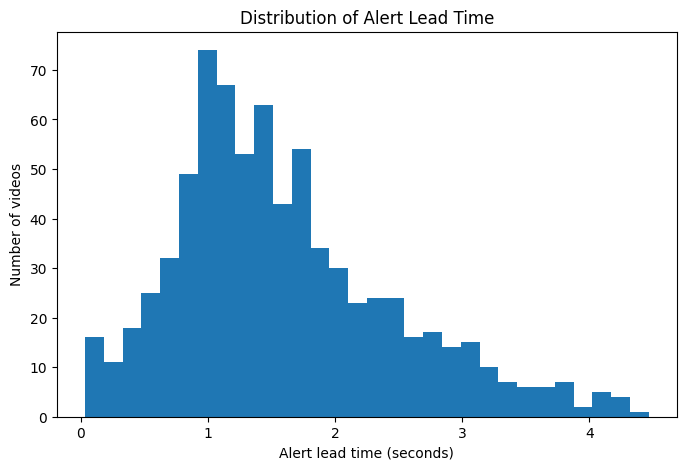

In [34]:
plt.figure(figsize=(8, 5))

plt.hist(
    positive["alert_lead_time"],
    bins=30
)

plt.xlabel("Alert lead time (seconds)")
plt.ylabel("Number of videos")
plt.title("Distribution of Alert Lead Time")

plt.show()

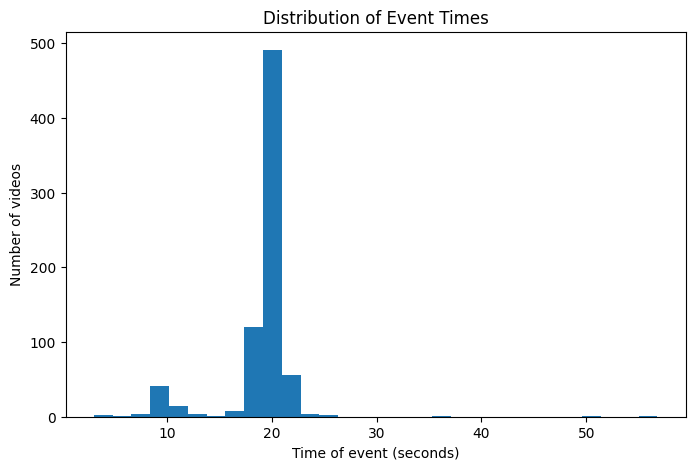

In [35]:
plt.figure(figsize=(8, 5))

plt.hist(
    positive["time_of_event"],
    bins=30
)

plt.xlabel("Time of event (seconds)")
plt.ylabel("Number of videos")
plt.title("Distribution of Event Times")

plt.show()

### Interpretation

The event-time distribution confirms that events are not located at one
fixed point in the videos.

Although many events occur around the 20-second region, there are also
videos with substantially earlier or later events.

This reinforces the need to construct clips relative to each video's
individual event timestamp.

## 7. Connecting CSV IDs to Video Files

The CSV contains an `id` for every video.

The training videos are stored in:

    data/raw/train/

We now verify that the IDs in the CSV correspond to the MP4 filenames.

For example:

    CSV id = 822

should correspond to:

    train/00822.mp4

This is important because our future data pipeline will need to connect
each metadata row with its corresponding video.

In [36]:
train_video_dir = DATA_DIR / "train"

video_files = list(train_video_dir.glob("*.mp4"))

print("Number of training videos:", len(video_files))

print("\nFirst 10 videos:")

for video in video_files[:10]:
    print(video.name)

Number of training videos: 1500

First 10 videos:
01811.mp4
01805.mp4
01193.mp4
01839.mp4
01187.mp4
00272.mp4
00500.mp4
00266.mp4
01178.mp4
00528.mp4


In [37]:
print(
    "CSV IDs:",
    df["id"].min(),
    "to",
    df["id"].max()
)

CSV IDs: 0 to 2139


In [38]:
sample_ids = df["id"].head(10)

for video_id in sample_ids:
    video_path = train_video_dir / f"{video_id:05d}.mp4"
    
    print(
        video_id,
        "->",
        video_path.exists(),
        video_path
    )

1924 -> True data/raw/train/01924.mp4
822 -> True data/raw/train/00822.mp4
1429 -> True data/raw/train/01429.mp4
208 -> True data/raw/train/00208.mp4
1904 -> True data/raw/train/01904.mp4
72 -> True data/raw/train/00072.mp4
1486 -> True data/raw/train/01486.mp4
1171 -> True data/raw/train/01171.mp4
128 -> True data/raw/train/00128.mp4
1518 -> True data/raw/train/01518.mp4


In [39]:
missing_videos = []

for video_id in df["id"]:
    video_path = train_video_dir / f"{video_id:05d}.mp4"
    
    if not video_path.exists():
        missing_videos.append(video_id)

print("Missing training videos:", len(missing_videos))

if len(missing_videos) > 0:
    print("Missing IDs:", missing_videos[:20])

Missing training videos: 0


# Dataset Exploration Summary

## Dataset structure

The Nexar training dataset contains:

- **1,500 training videos**
- **750 negative videos**
- **750 positive videos**
- A balanced class distribution of **50% / 50%**

The training metadata contains four columns:

- `id`
- `time_of_event`
- `time_of_alert`
- `target`

## Missing values

`time_of_event` and `time_of_alert` contain 750 missing values each.

These missing values correspond to the negative examples, where there is
no collision/near-miss event and therefore no event or alert timestamp.

The missing timestamps should therefore be treated as meaningful rather
than automatically removed.

## Event timing

Positive videos have variable event times.

Observed event-time statistics:

- Mean: approximately **19.10 s**
- Median: approximately **19.80 s**
- Minimum: approximately **3.03 s**
- Maximum: approximately **56.80 s**

Therefore, event timestamps must be handled on a per-video basis rather
than assuming that every event occurs at the same time.

## Alert timing

The calculated alert lead time is:

    alert_lead_time = time_of_event - time_of_alert

Observed statistics:

- Mean: approximately **1.60 s**
- Median: approximately **1.43 s**
- Minimum: approximately **0.03 s**
- Maximum: approximately **4.47 s**

The variation shows that the amount of warning available before an event
differs substantially between videos.

The approximately **1.43-second median alert lead time** provides useful
context for the planned 1.5-second prediction horizon, although it should
not be treated as a universal human-warning threshold.

## Implications for the project

These observations support a time-to-event prediction experiment.

For positive videos, future clips can be constructed relative to the
individual event timestamp:

    TTE = 0.5 seconds
    TTE = 1.0 seconds
    TTE = 1.5 seconds

For example, if:

    time_of_event = 19.5 s

then a 1.5-second TTE observation should end at:

    19.5 - 1.5 = 18.0 s

The model must not receive frames occurring after the selected prediction
point because those frames could contain information from the event itself.

## Important experimental consideration

The training/test split must occur at the **video level before generating
clips**.

Multiple clips generated from the same original video must never be split
between training and testing, because that could cause temporal/data
leakage.

## Current conclusion

The metadata is sufficiently understood to move to the next stage:

**Inspecting the actual MP4 videos and verifying their video properties,
timestamps, duration, FPS, resolution, and frame structure.**

No large-scale preprocessing has been performed yet.

The original 30 GB dataset remains unchanged in:

    data/raw/